<center><h1>Loke_Eliza_HW6</h1></center>

Name: Eliza Loke
<br>
Github Username: eliza-data
<br>
USC ID: 9840375742

## 1. Tree-Based Methods

Import packages

In [123]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_curve, roc_auc_score, accuracy_score
from sklearn.tree import DecisionTreeClassifier
from imblearn.ensemble import BalancedRandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

### (a) Download the APS Failure data

In [124]:
############ Directory setup for data files ############
NOTEBOOK_DIR = Path('.').resolve()

if NOTEBOOK_DIR.name.strip().lower() in ['notebook', 'notebooks']:
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    PROJECT_ROOT = NOTEBOOK_DIR

# Step up to the project root directory, then point to folder
DATA_DIR = PROJECT_ROOT / 'APS_Failure' 

# Set the train and test dataset files
TRAIN_FILE = DATA_DIR / 'aps_failure_training_set.csv'
TEST_FILE = DATA_DIR / 'aps_failure_test_set.csv'

# Checks if the data directory exists
if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Data directory not found at: {DATA_DIR}\n"
        "Check 'APS_Failure' folder located in the project root folder."
    )

print(f"Project Root: {PROJECT_ROOT}")
print(f"Dataset Directory: {DATA_DIR}")
print(f"Dataset File: {TRAIN_FILE}")
print(f"Dataset File: {TEST_FILE}")

############ Load the train and test datasets ############

# Exammines the first 23 lines of the TRAINING dataset file to understand its structure and content.
with open(TRAIN_FILE, 'r', encoding='utf-8') as file:
    for i in range(23):
        print(f"Line {i+1}: {file.readline().strip()}")

# Exammines the first 23 lines of the TEST dataset file to understand its structure and content.
with open(TEST_FILE, 'r', encoding='utf-8') as file:
    for i in range(23):
        print(f"Line {i+1}: {file.readline().strip()}")

# Load the training and test datasets into pandas DataFrames, treating 'na' as missing values, converting to NaN. 
# Skipping the first 20 lines in both datasets, which contain metadata, to start reading the data line 21.

training_data = pd.read_csv(
    TRAIN_FILE,
    skiprows=20,
    na_values='na'
)

test_data = pd.read_csv(
    TEST_FILE,
    skiprows=20,
    na_values='na'
)

# Display dataset dimensions

print("Training dataset dimensions:", training_data.shape)
print("Test dataset dimensions:", test_data.shape)

# Verify the column names in the training dataset 
print(training_data.columns.tolist())


Project Root: /Users/eliza/Desktop/DSCI 552 Machine Learning /F26/Homework Folder/Homework 6 Data
Dataset Directory: /Users/eliza/Desktop/DSCI 552 Machine Learning /F26/Homework Folder/Homework 6 Data/APS_Failure
Dataset File: /Users/eliza/Desktop/DSCI 552 Machine Learning /F26/Homework Folder/Homework 6 Data/APS_Failure/aps_failure_training_set.csv
Dataset File: /Users/eliza/Desktop/DSCI 552 Machine Learning /F26/Homework Folder/Homework 6 Data/APS_Failure/aps_failure_test_set.csv
Line 1: This file is part of APS Failure and Operational Data for Scania Trucks.
Line 2: 
Line 3: Copyright (c) <2016> <Scania CV AB>
Line 4: 
Line 5: This program (APS Failure and Operational Data for Scania Trucks) is
Line 6: free software: you can redistribute it and/or modify
Line 7: it under the terms of the GNU General Public License as published by
Line 8: the Free Software Foundation, either version 3 of the License, or
Line 9: (at your option) any later version.
Line 10: 
Line 11: This program is di

### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Types of data imputation techniques for missing values

- Mean: Replaces missing values with the mean of the feature
- Median: Replaces missing values with the median of the feature
- Mode: Replaces missing values with the mode of the feature
- K-Nearest Neighbor (KNN): Calculate missing value based on similar ones of the feature
- Removal: Delete features containing missing values

#### (ii) Calculate the coefficient of variation

In [125]:
############ Calculate coefficients of variation for each feature in the training dataset ############

# Select the 170 independent features disregard 'class' column
features = training_data.drop(columns=['class'])

# Calculate the coefficient of variation for each feature
cv_values = features.std() / features.mean()    # C = s / m
                                                # s = sample standard deviation of the feature
                                                # m = sample mean of the feature

# Display CV values as a DataFrame
cv_df = cv_values.reset_index()
cv_df.columns = ['Feature', 'CV']
cv_df

,Feature,CV
0,aa_000,2.450938
1,ab_000,4.878040
2,ac_000,2.232705
3,ad_000,211.962417
4,ae_000,23.689732
...,...,...
165,ee_007,4.990467
166,ee_008,3.240179
167,ee_009,5.658710
168,ef_000,48.232568


#### (iii) Plot a correlation matrix

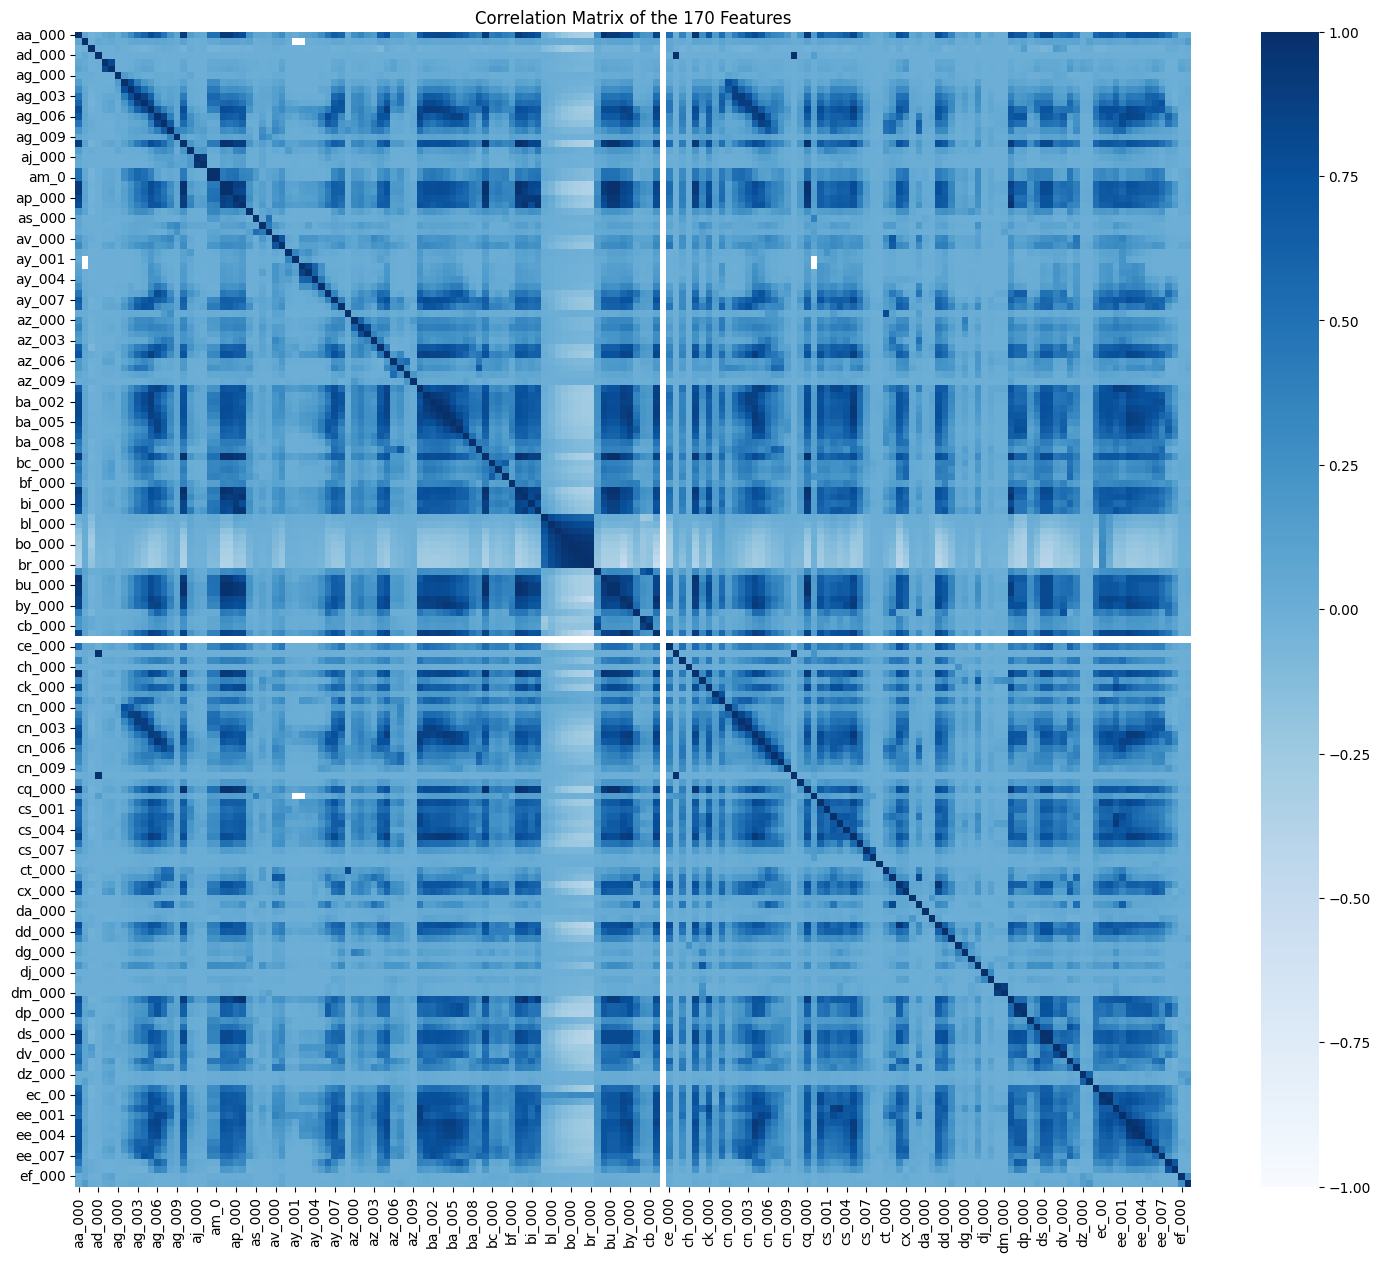

In [126]:
############ Create a correlation matrix ############

# Select the 170 independent features disregard 'class' column
features = training_data.drop(columns=['class'])

# Calculate the correlation matrix using Pandas and Seaborn
correlation_matrix = features.corr()

# Plot the correlation matrix
plt.figure(figsize=(18, 15))
sns.heatmap(correlation_matrix, cmap='Blues', vmin=-1, vmax=1,center=0)

plt.title('Correlation Matrix of the 170 Features')
plt.show()



#### (iv) Make scatter plots and box plots

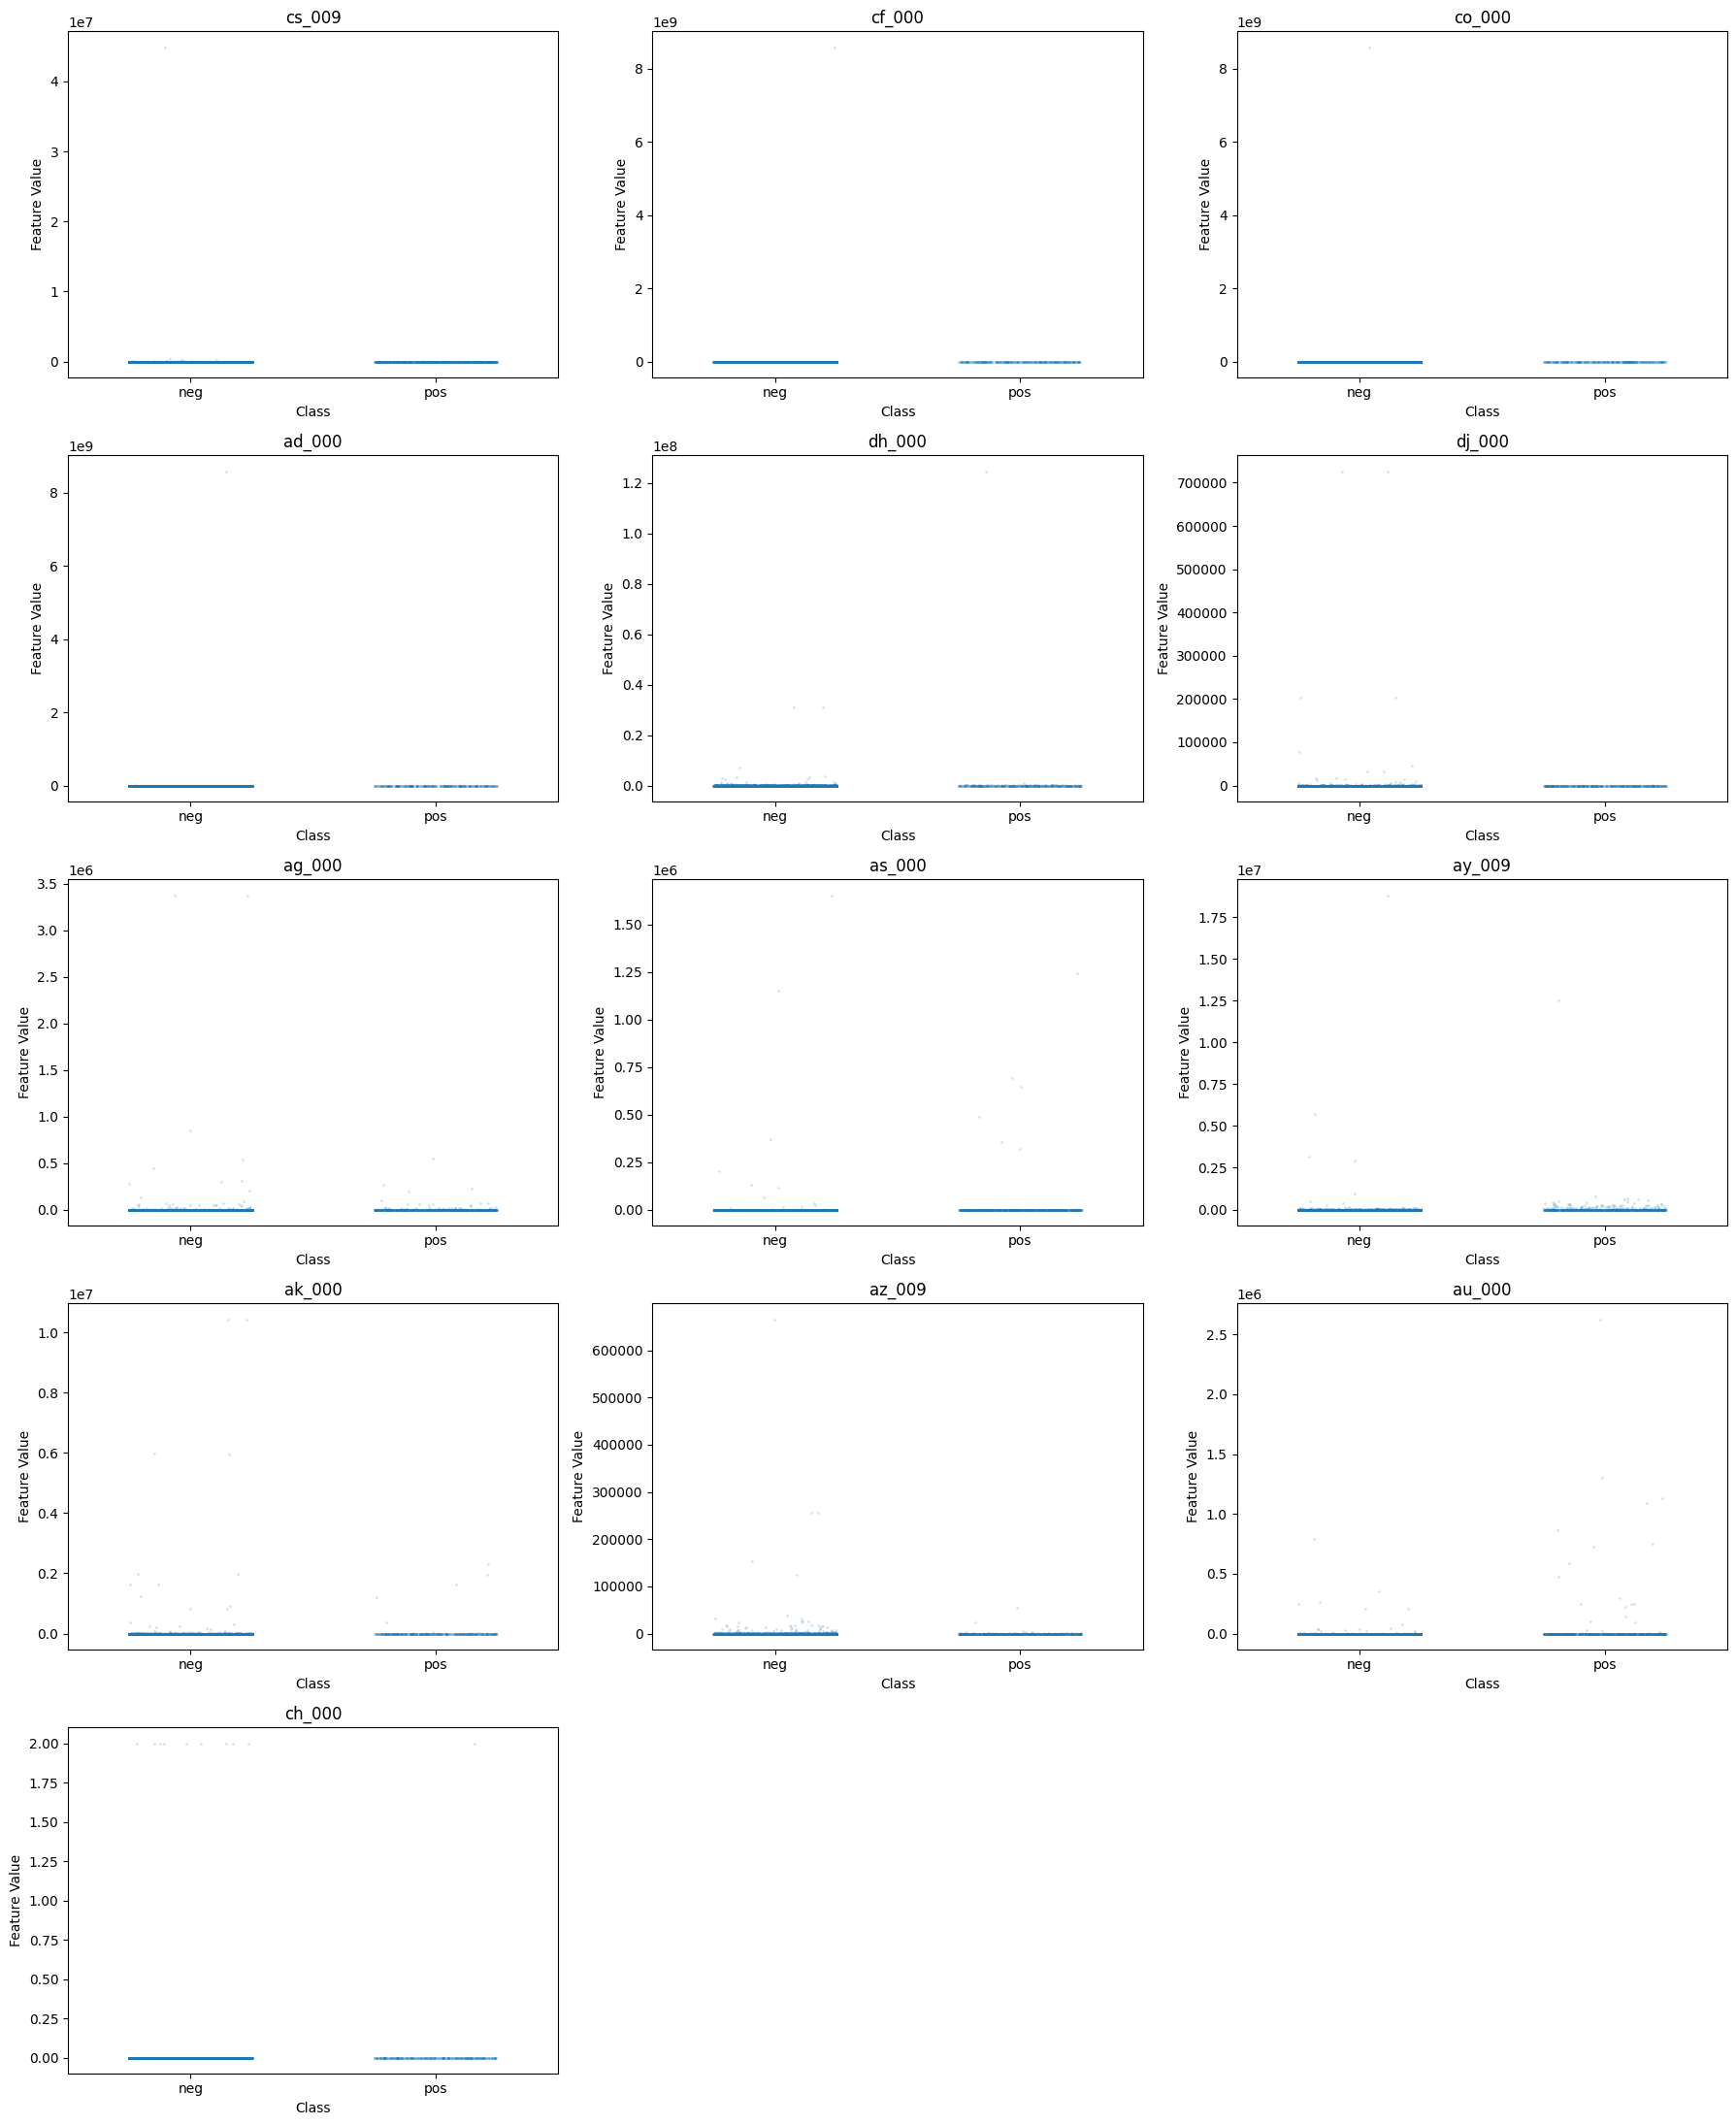

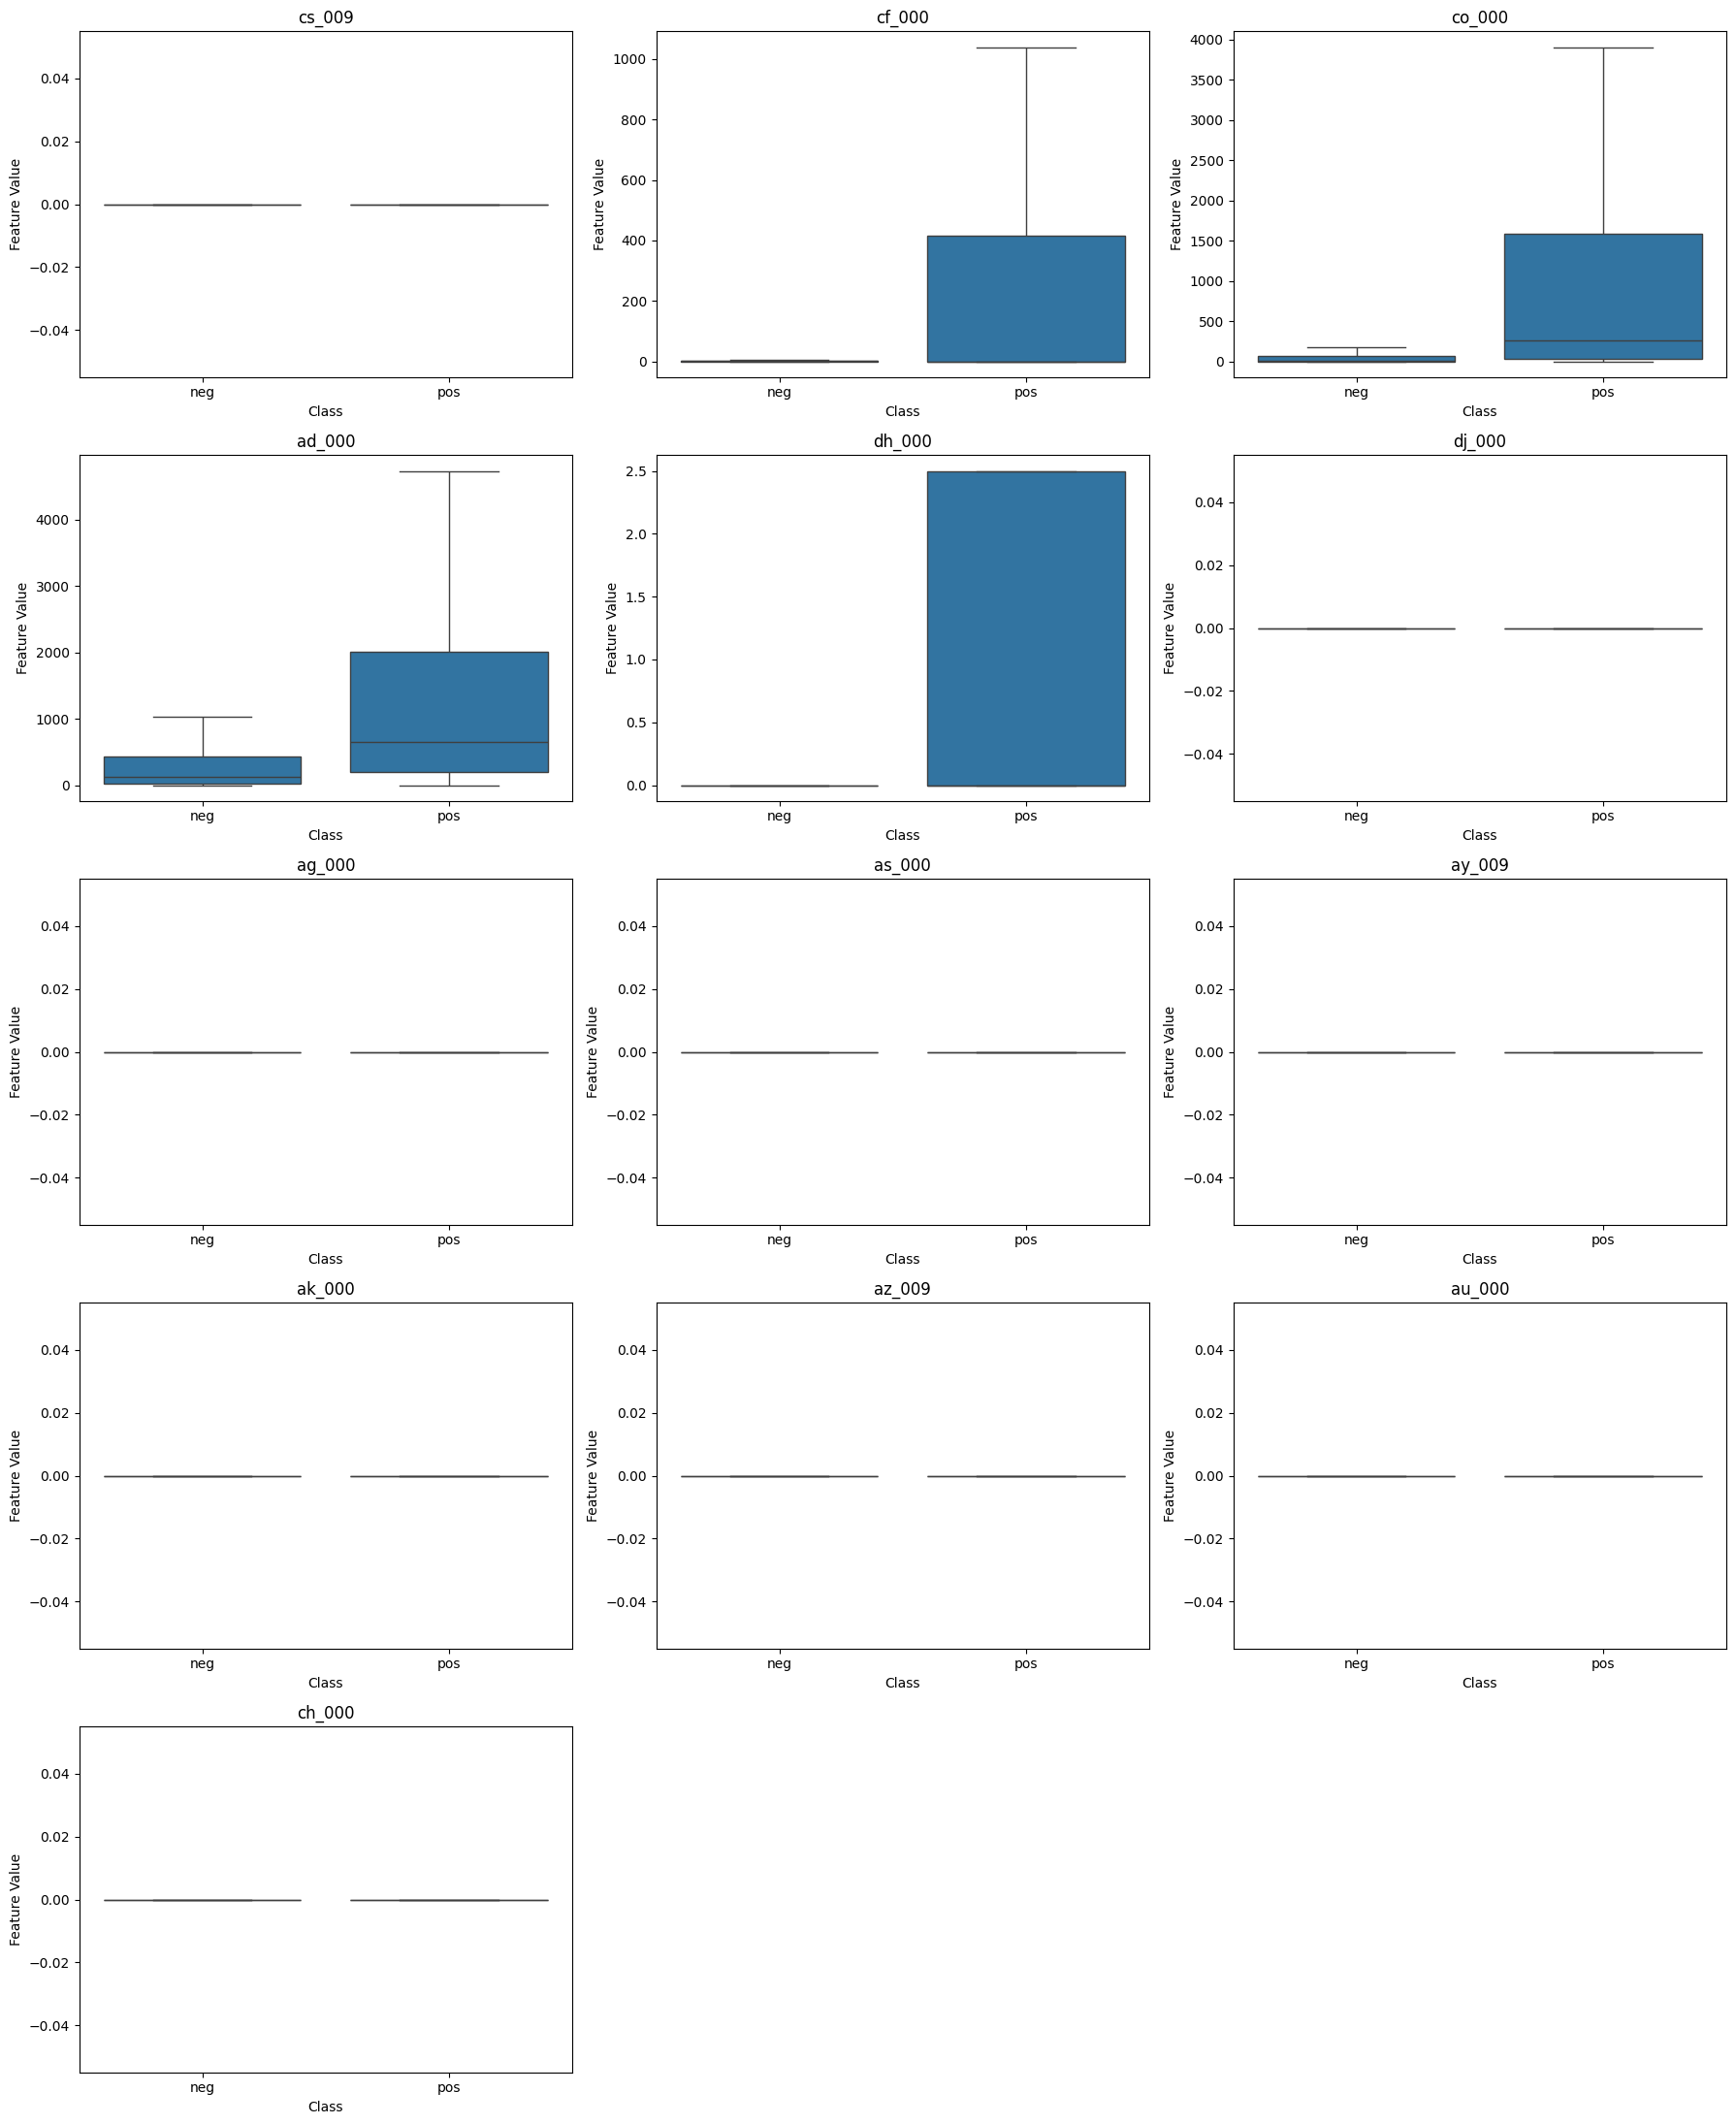

,Zero Percentage (%)
cs_009,94.04
cf_000,35.78
co_000,21.32
ad_000,3.35
dh_000,81.68
dj_000,92.99
ag_000,98.56
as_000,98.92
ay_009,97.98
ak_000,92.04


In [127]:
############ Select features with the highest coefficient of variation (CV) ############

#  ⌊√170⌋  = 13 (rounded to nearest integer)
# Find top 13 features with the highest CV values
top_features = cv_df.nlargest(13, 'CV')
top_features



############ Scatter Plots ############ 
# Create scatter plots for the 13 selected features
fig, axes = plt.subplots(5, 3, figsize=(18, 22))
axes = axes.flatten()

for i, feature in enumerate(top_features['Feature']):
    sns.stripplot(
        data=training_data,
        x='class',
        y=feature,
        ax=axes[i],
        jitter=0.25,
        alpha=0.2,
        size=2
    )

    axes[i].set_title(feature)
    axes[i].set_xlabel('Class')
    axes[i].set_ylabel('Feature Value')

# Remove unused subplot spaces
for i in range(13, 15):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()


############ Box Plots ############ 

# Create box plots for the 13 selected features
fig, axes = plt.subplots(5, 3, figsize=(18, 22))
axes = axes.flatten()

for i, feature in enumerate(top_features['Feature']):
    sns.boxplot(
        data=training_data,
        x='class',
        y=feature,
        ax=axes[i],
        showfliers=False
    )

    axes[i].set_title(feature)
    axes[i].set_xlabel('Class')
    axes[i].set_ylabel('Feature Value')

# Remove unused subplot spaces
for i in range(13, 15):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

# Examine the descriptive statistics of the 13 selected features
top_features = cv_df.nlargest(13, 'CV')

# Examine descriptive statistics for those features
training_data[top_features['Feature']].describe().T

# Calculate the percentage of zero values for each selected feature
zero_percentage = (
    (training_data[top_features['Feature']] == 0).mean() * 100
).round(2)

# Checks the percentage of zero values for each selected feature 
zero_percentage.to_frame(name='Zero Percentage (%)')

Features with highest CV Analysis 
The 13 features with highest CV distributed across negative (neg) and positive (pos) classes

Scatter Plot 
Based on the calculated table in percentage of zero values for each feature, it appears the 13 highest CV features contains more zero values. The scatter plot distribution demonstrated a high concentration near zero for both 'neg' and 'pos' classes. It's difficult to extract viable significance from these features. Futher examination is needed to distingish the minimal differences between each feature and classes. 

Box Plot
Only 4 of the box plots offer visable different distributions between the 'neg' and 'pos' classes. The following features, cf_000, co_000, and ad_000 show  variation with the positive classes compared with negative classes. The plots for co_000 and ad_000 display the positive classes to have high median values. While negative observations are concentrated around zero and variation among positive observations for plotted feature dh_000. The rest of the box plots appear to have similar distribution concentrated at zero.

Overall, further statistical analysis needs to be conducted to evaluate the features as neither scatter plots or box plots provide useful visualizations to distinguish the significance between the 'neg' and 'pos' classes.

#### (v) Is this data set imbalanced?

In [128]:
# Number of positive and negative 
class_counts = training_data['class'].value_counts()

# Calculate the percentage of each class
class_percentages = training_data['class'].value_counts(normalize=True) * 100

# Display results as a DataFrame
class_distribution = pd.DataFrame({
    'Count': class_counts,
    'Percentage (%)': class_percentages.round(2)
})

class_distribution

,Count,Percentage (%)
class,,
neg,59000,98.33
pos,1000,1.67


Positive and negative class distribution and data imbalance:

The training dataset contains 59,000 negative (98.33%) and 1,000 positive (1.67%) observations. This demonstrated a highly imbalanced considering the entire training dataset has 60,000 observations, therefore the ratio leans towards the negative class. To conduct further statistical analysis, these factors need to taken into account. For instance, if the model predicts negative observations it will achieve high accuracy, but disregards the positive observations. 

### (c) Train a random forest

Training features: (60000, 170)
Training labels: (60000,)
Test features: (16000, 170)
Test labels: (16000,)
Missing values in training: 0
Missing values in test: 0
Training AUC: 1.0
Test AUC: 0.9946067626666667


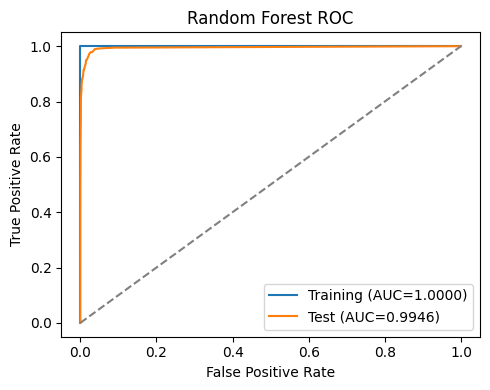

Training Confusion Matrix:
[[59000     0]
 [    0  1000]]
Test Confusion Matrix:
[[15609    16]
 [  111   264]]

Training Misclassification Rate: 0.0079375
Test Error Rate: 0.0079375

OOB Error: 0.0059833333333333405
Test Error Rate: 0.0079375


In [129]:
############ 1. Prepare training and test dataset ############ 
# Separate training data into features and target
dep_train = training_data.drop(columns=['class'])
ind_train = training_data['class']

# Separate test data into features and target
dep_test = test_data.drop(columns=['class'])
ind_test = test_data['class']




############ 2. Handle missing values using median imputation ############
# Initialize the median imputer
imputer = SimpleImputer(strategy='median')

# Fit the imputer using training features and transform training features
dep_train_imputed = pd.DataFrame(
    imputer.fit_transform(dep_train),
    columns=dep_train.columns,
    index=dep_train.index
)

# Apply the training imputation values to the test features
dep_test_imputed = pd.DataFrame(
    imputer.transform(dep_test),
    columns=dep_test.columns,
    index=dep_test.index
)




############ 3. Check dimensions and missing values after imputation ############
# Check dimensions
print("Training features:", dep_train_imputed.shape)
print("Training labels:", ind_train.shape)

print("Test features:", dep_test_imputed.shape)
print("Test labels:", ind_test.shape)

# Check remaining missing values
print("Missing values in training:", dep_train_imputed.isna().sum().sum())
print("Missing values in test:", dep_test_imputed.isna().sum().sum())




############ 4. Train Random Forest ############ 
# Build multiple decision trees using bootstrap samples and random feature subsets.

# Initialize the Random Forest classifier (DO NOT account for class imbalance)
random_forest = RandomForestClassifier(
    n_estimators=100, 
    random_state=565,
    oob_score=True, # calculate out-of-bag error
    n_jobs=-1 # controls number of CPU processors used (training speed)
)

# Train the Random Forest using the training dataset
random_forest.fit(dep_train_imputed, ind_train)




############ 5. Generate predictions and evaluate model performance ############ 
# Predict classes and positive-class probabilities for training and test observations.

# Generate predicted class labels
train_pred = random_forest.predict(dep_train_imputed)
test_pred = random_forest.predict(dep_test_imputed)

# Generate predicted probabilities for each class
train_prob = random_forest.predict_proba(dep_train_imputed)
test_prob = random_forest.predict_proba(dep_test_imputed)

# Identify the column corresponding to the positive class ('pos')
pos_index = list(random_forest.classes_).index('pos')

# Extract positive-class probabilities
train_pos_prob = train_prob[:, pos_index]
test_pos_prob = test_prob[:, pos_index]




############# 6. Calculate ROC and AUC ############
# Training ROC and AUC
train_fpr, train_tpr, _ = roc_curve(
    ind_train, train_pos_prob, pos_label='pos'
)
train_auc = roc_auc_score(ind_train, train_pos_prob)

# Test ROC and AUC
test_fpr, test_tpr, _ = roc_curve(
    ind_test, test_pos_prob, pos_label='pos'
)
test_auc = roc_auc_score(ind_test, test_pos_prob)

# Display AUC results
print("Training AUC:", train_auc)
print("Test AUC:", test_auc)

# Plot ROC curves
plt.figure(figsize=(5, 4))
plt.plot(train_fpr, train_tpr, label=f'Training (AUC={train_auc:.4f})')
plt.plot(test_fpr, test_tpr, label=f'Test (AUC={test_auc:.4f})')
plt.plot([0, 1], [0, 1], '--', color='gray')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Random Forest ROC')
plt.legend()
plt.tight_layout()
plt.show()




############# 7. Calculate confusion matrices ############
# Training confusion matrix
train_cm = confusion_matrix(
    ind_train,
    train_pred,
    labels=['neg', 'pos']
)

# Test confusion matrix
test_cm = confusion_matrix(
    ind_test,
    test_pred,
    labels=['neg', 'pos']
)

print("Training Confusion Matrix:")
print(train_cm)

print("Test Confusion Matrix:")
print(test_cm)



############# 8. Calculate misclassification rates ############

# Training misclassification rate
original_test_error = (train_pred != ind_train).mean()

# Test misclassification rate
original_test_error = (test_pred != ind_test).mean()

print("\nTraining Misclassification Rate:", original_test_error)
print("Test Error Rate:", original_test_error)



############# 9. Calculate OOB error and compare with test error ############

# Calculate OOB error
oob_error = 1 - random_forest.oob_score_

print("\nOOB Error:", oob_error)
print("Test Error Rate:", original_test_error)



1(c) OOB Error vs. Test Error Rate Comparison
OOB Error: 0.5983%
Test Error Rate: 0.7938%
Difference is approximately 0.1954%. Since the difference in error is small, it indicates the OOB error is reasonable consistent with the model's performance. 


### (d) Research class imbalance in random forest

###1(d)
### Part 1: Research Method


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/imblearn/ensemble/_forest.py:827: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


Training AUC: 0.9956086101694916
Test AUC: 0.9914619733333334


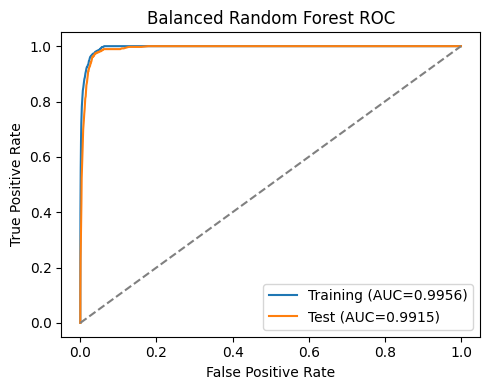

Training Confusion Matrix:
[[56145  2855]
 [   14   986]]
Test Confusion Matrix:
[[14899   726]
 [    8   367]]
Training Misclassification Rate: 0.045875
Test Misclassification Rate: 0.045875
Original Random Forest OOB Error: 0.0059833333333333405
Balanced Random Forest OOB Error: 0.028200000000000003

Original Random Forest Test Error: 0.0079375
Balanced Random Forest Test Error: 0.045875
Observations without OOB predictions: 31742
Total training observations: 60000


In [130]:
############ 1. Train Balanced Random Forest ############

balanced_random_forest = BalancedRandomForestClassifier(
    n_estimators=100,
    sampling_strategy='all',
    replacement=True,
    bootstrap=True,
    oob_score=True,
    random_state=565,
    n_jobs=-1
)

balanced_random_forest.fit(dep_train_imputed, ind_train)



############ 2. Generate predictions ############

# Generate predicted class labels
train_pred = balanced_random_forest.predict(dep_train_imputed)
test_pred = balanced_random_forest.predict(dep_test_imputed)

# Generate predicted probabilities for each class
train_prob = balanced_random_forest.predict_proba(dep_train_imputed)
test_prob = balanced_random_forest.predict_proba(dep_test_imputed)

# Identify the column corresponding to the positive class ('pos')
pos_index = list(balanced_random_forest.classes_).index('pos')

# Extract positive-class probabilities
train_pos_prob = train_prob[:, pos_index]
test_pos_prob = test_prob[:, pos_index]



############ 3. Calculate ROC and AUC ############

# Training ROC and AUC
train_fpr, train_tpr, _ = roc_curve(
    ind_train, train_pos_prob, pos_label='pos'
)
train_auc = roc_auc_score(ind_train, train_pos_prob)

# Test ROC and AUC
test_fpr, test_tpr, _ = roc_curve(
    ind_test, test_pos_prob, pos_label='pos'
)
test_auc = roc_auc_score(ind_test, test_pos_prob)

# Display AUC results
print("Training AUC:", train_auc)
print("Test AUC:", test_auc)

# Plot ROC curves
plt.figure(figsize=(5, 4))
plt.plot(train_fpr, train_tpr, label=f'Training (AUC={train_auc:.4f})')
plt.plot(test_fpr, test_tpr, label=f'Test (AUC={test_auc:.4f})')
plt.plot([0, 1], [0, 1], '--', color='gray')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Balanced Random Forest ROC')
plt.legend()
plt.tight_layout()
plt.show()



############ 3. Calculate confusion matrices ############

# Training confusion matrix
train_cm = confusion_matrix(
    ind_train,
    train_pred,
    labels=['neg', 'pos']
)

# Test confusion matrix
test_cm = confusion_matrix(
    ind_test,
    test_pred,
    labels=['neg', 'pos']
)

print("Training Confusion Matrix:")
print(train_cm)

print("Test Confusion Matrix:")
print(test_cm)


############ 4. Calculate misclassification rates ############

# Training misclassification rate
balanced_test_error = 1 - accuracy_score(ind_train, train_pred)

# Test misclassification rate
balanced_test_error = 1 - accuracy_score(ind_test, test_pred)

print("Training Misclassification Rate:", balanced_test_error)
print("Test Misclassification Rate:", balanced_test_error)


############ 5. Calculate OOB error ############

# Original Random Forest (Q1c)
original_oob_error = 1 - random_forest.oob_score_

# Balanced Random Forest (Q1d)
balanced_oob_error = 1 - balanced_random_forest.oob_score_

# Display OOB errors
print("Original Random Forest OOB Error:", original_oob_error)
print("Balanced Random Forest OOB Error:", balanced_oob_error)

# Compare OOB errors with test misclassification rates
print("\nOriginal Random Forest Test Error:", original_test_error)
print("Balanced Random Forest Test Error:", balanced_test_error) 

############ Check observations without OOB predictions ############

# Identify observations with zero OOB probabilities
missing_oob = np.all(oob_prob == 0, axis=1)

print("Observations without OOB predictions:", missing_oob.sum())
print("Total training observations:", len(oob_prob))

1(d) 

(1) OOB Error vs. Test Error Rate Comparison
Balanced Random Forest OOB Error: 0.028200000000000003
Balanced Random Forest Test Error: 0.045875
The Balanced Random Forest OOB Error (2.82%) is a lower rate than Test Error (4.59%). This difference in error is greater than the original Random Forest. The use of balanced sampling was used to interpret the OOB, which impacted the selection for individual trees. A warning was included during the training indicating some training observations did not receive enough OOB predictions for the model to calculate a reliable OOB estimate which hinders the overall OOB results. If some observations did not receive an OOB prediction, it would disproportionately impact both majority and minority classes. For this reason, the OOB error is not completely reliable. 

(2) Balanced Random Forest (1d) vs. Original Random Forest (1c) Comparison
Balanced Random Forest with balanced sampling was used to address the class imbalance. This method adjusts the class distribution used to train individual trees by reducing the majority and increasing the minority observations. It resulted in substantial improvements in detecting minority classes, with an increase in positive recall rates from 70.40% to 97.87% (calculated using the recall formula with results from the confusion matrix) and a reduction in false negatives from 111 to 8 (results from the train confusion matrix in 1c and 1d). Although, false positives increased from 16 to 726, and positive-class precision decreased from 94.29% to 33.58%. 

Both models Balanced Random Forest (0.9915) and the original Random Forest (0.9946) with higher values still had comparable AUC results. In the OOB error rates, original Random Forest also had a lower OOB error (0.60%) than the Balanced Random Forest (2.82%). As mentioned above, the OOB results for the balanced model is could potentially be interpretted as bias. 

Balanced Random Forest sampling improved the detection of the minority positive class but increased false positives. Therefore, the Balanced Random Forest was more effective at identifying positive cases, while the original Random Forest performed efficiently with accuracy and precision.

### (e) XGBoost and Model Trees

0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0

Best alpha: 0.001
Best CV accuracy: 0.99365
Best CV error: 0.006349999999999967
Training Confusion Matrix:
[[59000     0]
 [    1   999]]

Test Confusion Matrix:
[[15604    21]
 [   87   288]]
Training Misclassification Rate: 1.666666666666483e-05
Test Misclassification Rate: 0.006750000000000034


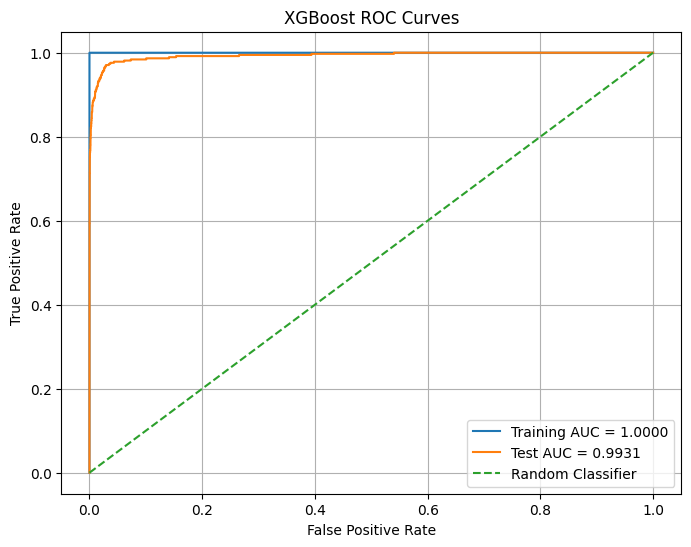

Training AUC: 0.9999999830508475
Test AUC: 0.9931431253333333


In [131]:
############ 1. Alpha using 5-fold cross-validation ############
# Encode the target labels
ind_train_xgb = ind_train.map({'neg': 0, 'pos': 1})
ind_test_xgb = ind_test.map({'neg': 0, 'pos': 1})

# Set up 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=552
)

# Initialize the XGBoost classifier
xgb_model = XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=552,
    n_jobs=-1
)

# Values of alpha to evaluate
param_grid = {
    'reg_alpha': [0, 0.001, 0.01, 0.1, 1, 10]
}



############ 2. Train the final XGBoost model ############ 
# Search for the best alpha using 5-fold cross-validation
xgb_cv = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1
)

xgb_cv.fit(dep_train_imputed, ind_train_xgb)

# Display the best alpha and its cross-validation accuracy
print("Best alpha:", xgb_cv.best_params_['reg_alpha'])
print("Best CV accuracy:", xgb_cv.best_score_)
print("Best CV error:", 1 - xgb_cv.best_score_)

# Train the final XGBoost model using the best alpha
xgb_model_final = XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    tree_method='hist',
    reg_alpha=xgb_cv.best_params_['reg_alpha'],
    random_state=552,
    n_jobs=-1
)

xgb_model_final.fit(dep_train_imputed, ind_train_xgb)

############ 3. Generate predictions and predicted probabilities ############
# Generate class predictions
train_pred = xgb_model_final.predict(dep_train_imputed)
test_pred = xgb_model_final.predict(dep_test_imputed)

# Generate predicted probabilities for the positive class
train_prob = xgb_model_final.predict_proba(dep_train_imputed)[:, 1]
test_prob = xgb_model_final.predict_proba(dep_test_imputed)[:, 1]



############ 4. Calculate confusion matrices ############
# Training confusion matrix
train_cm = confusion_matrix(ind_train_xgb, train_pred)
print("Training Confusion Matrix:")
print(train_cm)

# Test confusion matrix
test_cm = confusion_matrix(ind_test_xgb, test_pred)
print("\nTest Confusion Matrix:")
print(test_cm)


############ 5. Calculate misclassification rates ############
# Calculate training and test misclassification rates
train_error = 1 - accuracy_score(ind_train_xgb, train_pred)
test_error = 1 - accuracy_score(ind_test_xgb, test_pred)

print("Training Misclassification Rate:", train_error)
print("Test Misclassification Rate:", test_error)

############ 6. Calculate ROC and AUC ############ 
# Calculate training ROC and AUC
train_fpr, train_tpr, _ = roc_curve(ind_train_xgb, train_prob)
train_auc = roc_auc_score(ind_train_xgb, train_prob)

# Calculate test ROC and AUC
test_fpr, test_tpr, _ = roc_curve(ind_test_xgb, test_prob)
test_auc = roc_auc_score(ind_test_xgb, test_prob)

# Plot ROC curves
plt.figure(figsize=(8, 6))

plt.plot(train_fpr, train_tpr, label=f'Training AUC = {train_auc:.4f}')
plt.plot(test_fpr, test_tpr, label=f'Test AUC = {test_auc:.4f}')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('XGBoost ROC Curves')
plt.legend()
plt.grid()
plt.show()

print("Training AUC:", train_auc)
print("Test AUC:", test_auc)

### (f) Use SMOTE to pre-process your data

Best alpha: 0
Best CV accuracy: 0.9934166666666666
Best CV error: 0.0065833333333333854
Selected alpha: 0
Final model trained using the full training set.
Training Confusion Matrix:
[[59000     0]
 [    1   999]]

Test Confusion Matrix:
[[15580    45]
 [   66   309]]
Training Misclassification Rate: 1.666666666666483e-05
Test Misclassification Rate: 0.006937500000000041


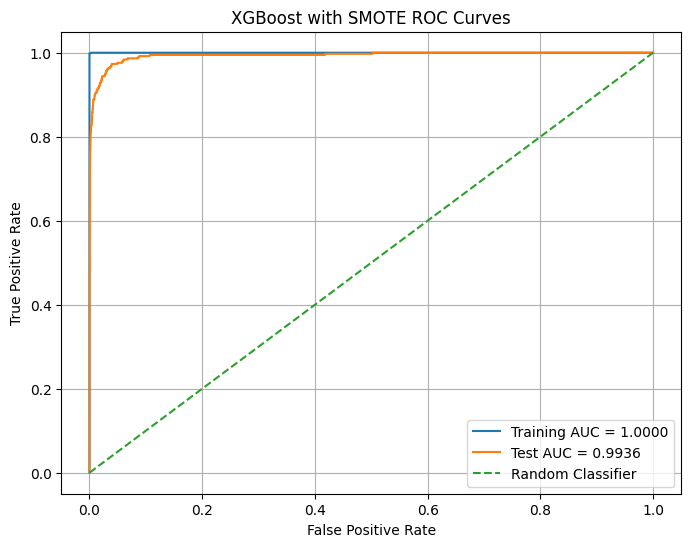

Training AUC: 0.9999969576271186
Test AUC: 0.9935511893333333


,Model,Best Alpha,CV Error,Training Error,Test Error,Training AUC,Test AUC
0,Without SMOTE,0.001,0.006350,0.000017,0.006750,1.000000,0.993143
1,With SMOTE,0.000,0.006583,0.000017,0.006938,0.999997,0.993551


In [132]:
############ 1. Find the best alpha using cross-validation ############
# Set up 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=552
)

# Create a pipeline with imputation, SMOTE, and XGBoost
smote_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('smote', SMOTE(random_state=552)),
    ('xgb', XGBClassifier(
        objective='binary:logistic',
        eval_metric='logloss',
        tree_method='hist',
        random_state=552,
        n_jobs=-1
    ))
])

# Values of alpha to evaluate
param_grid = {
    'xgb__reg_alpha': [0, 0.01, 0.1, 1, 10]
}

# Search for the best alpha using cross-validation
smote_xgb_cv = GridSearchCV(
    estimator=smote_pipeline,
    param_grid=param_grid,
    scoring='accuracy',
    cv=cv,
    n_jobs=1
)

# Fit using the original training data
smote_xgb_cv.fit(dep_train, ind_train_xgb)

# Display results
print("Best alpha:", smote_xgb_cv.best_params_['xgb__reg_alpha'])
print("Best CV accuracy:", smote_xgb_cv.best_score_)
print("Best CV error:", 1 - smote_xgb_cv.best_score_)


############ 2. Train the final XGBoost model with SMOTE ############
# GridSearchCV automatically refits the best pipeline on the full training set
smote_xgb_final = smote_xgb_cv.best_estimator_

print("Selected alpha:", smote_xgb_cv.best_params_['xgb__reg_alpha'])
print("Final model trained using the full training set.")



############ 3. Generate training and test predictions ############
# Generate class predictions
smote_train_pred = smote_xgb_final.predict(dep_train)
smote_test_pred = smote_xgb_final.predict(dep_test)

# Generate probabilities for the positive class
smote_train_prob = smote_xgb_final.predict_proba(dep_train)[:, 1]
smote_test_prob = smote_xgb_final.predict_proba(dep_test)[:, 1]


############ 4. Calculate confusion matrices ############

from sklearn.metrics import confusion_matrix

# Training confusion matrix
smote_train_cm = confusion_matrix(ind_train_xgb, smote_train_pred)

print("Training Confusion Matrix:")
print(smote_train_cm)

# Test confusion matrix
smote_test_cm = confusion_matrix(ind_test_xgb, smote_test_pred)

print("\nTest Confusion Matrix:")
print(smote_test_cm)


############ 5. Calculate misclassification rates ############

from sklearn.metrics import accuracy_score

# Calculate training and test misclassification rates
smote_train_error = 1 - accuracy_score(ind_train_xgb, smote_train_pred)
smote_test_error = 1 - accuracy_score(ind_test_xgb, smote_test_pred)

print("Training Misclassification Rate:", smote_train_error)
print("Test Misclassification Rate:", smote_test_error)


############ 6. Calculate ROC curves and AUC ############

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Calculate training ROC and AUC
smote_train_fpr, smote_train_tpr, _ = roc_curve(
    ind_train_xgb, smote_train_prob
)
smote_train_auc = roc_auc_score(ind_train_xgb, smote_train_prob)

# Calculate test ROC and AUC
smote_test_fpr, smote_test_tpr, _ = roc_curve(
    ind_test_xgb, smote_test_prob
)
smote_test_auc = roc_auc_score(ind_test_xgb, smote_test_prob)

# Plot ROC curves
plt.figure(figsize=(8, 6))

plt.plot(
    smote_train_fpr,
    smote_train_tpr,
    label=f'Training AUC = {smote_train_auc:.4f}'
)

plt.plot(
    smote_test_fpr,
    smote_test_tpr,
    label=f'Test AUC = {smote_test_auc:.4f}'
)

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('XGBoost with SMOTE ROC Curves')
plt.legend()
plt.grid()
plt.show()

print("Training AUC:", smote_train_auc)
print("Test AUC:", smote_test_auc)


############ 7. Compare uncompensated and SMOTE models ############

import pandas as pd

# Generate predictions from the original Q1(e) model
base_train_pred = xgb_model_final.predict(dep_train_imputed)
base_test_pred = xgb_model_final.predict(dep_test_imputed)

# Generate positive-class probabilities
base_train_prob = xgb_model_final.predict_proba(dep_train_imputed)[:, 1]
base_test_prob = xgb_model_final.predict_proba(dep_test_imputed)[:, 1]

# Calculate original model's misclassification rates
base_train_error = 1 - accuracy_score(ind_train_xgb, base_train_pred)
base_test_error = 1 - accuracy_score(ind_test_xgb, base_test_pred)

# Calculate original model's AUC
base_train_auc = roc_auc_score(ind_train_xgb, base_train_prob)
base_test_auc = roc_auc_score(ind_test_xgb, base_test_prob)

# Create comparison table
comparison_results = pd.DataFrame({
    'Model': ['Without SMOTE', 'With SMOTE'],
    'Best Alpha': [
        xgb_cv.best_params_['reg_alpha'],
        smote_xgb_cv.best_params_['xgb__reg_alpha']
    ],
    'CV Error': [
        1 - xgb_cv.best_score_,
        1 - smote_xgb_cv.best_score_
    ],
    'Training Error': [
        base_train_error,
        smote_train_error
    ],
    'Test Error': [
        base_test_error,
        smote_test_error
    ],
    'Training AUC': [
        base_train_auc,
        smote_train_auc
    ],
    'Test AUC': [
        base_test_auc,
        smote_test_auc
    ]
})

display(comparison_results)


1(f): XGBoost Models With and Without SMOTE Comparison 
The results for the XGBoost model without SMOTE had a cross-validation error of 0.006350 and a test error of 0.006750. On the other hand, SMOTE had a cross-validation error of 0.006583, and the test error of to 0.006938. These results demonstrate SMOTE had increased these values. For AUC the values were similar as the following; 0.993143 without SMOTE and 0.993551 with SMOTE. SMOTE had lower cross-validation and test errors, while SMOTE had a  higher test AUC. SMOTE had minimal improvements for this dataset. 

## 2. ISLR 6.6.3

## 3. ISLR 6.6.5

## 4. ISLR 8.4.5

## 5. ISLR 9.7.3